# Data Preprocessing

Load the images, encode the labels, and split the dataset into training and validation setss

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

#### Before loading images into memory, we'll create a list containing each image's location and its category, We need to connect every image to its correct category before training a classification model.

In [21]:
dataset_path = Path("../data/Waste_Dataset")

image_paths = []
labels = []

for folder in sorted(dataset_path.iterdir()):
    if folder.is_dir():
        for image_file in folder.iterdir():
            if image_file.suffix.lower() in [".jpg", ".jpeg", ".png"]:
                image_paths.append(str(image_file))
                labels.append(folder.name)

print("Total images:", len(image_paths))
print("Total labels:", len(labels))
print("Categories:", len(set(labels)))

Total images: 4752
Total labels: 4752
Categories: 9


This converts category names into numbers

In [22]:
label_encoder = LabelEncoder()

encoded_labels = label_encoder.fit_transform(labels)

print("Category mapping:")

for category, number in zip(label_encoder.classes_, range(len(label_encoder.classes_))):
    print(f"{category}: {number}")

Category mapping:
1-Cardboard: 0
2-Food Organics: 1
3-Glass: 2
4-Metal: 3
5-Miscellaneous Trash: 4
6-Paper: 5
7-Plastic: 6
8-Textile Trash: 7
9-Vegetation: 8


Step 6: Split the dataset
We'll divide the 4,752 images into:
- 80% Training: Used to teach the model.
- 20% Validation: Used to evaluate the model during development.

In [23]:
X_train, X_val, y_train, y_val = train_test_split(
    image_paths,
    encoded_labels,
    test_size=0.2,
    random_state=42,
    stratify=encoded_labels
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))

Training images: 3801
Validation images: 951


Our images are 524 × 524. We'll resize them to 224 × 224, which is a common input size for CNN and MobileNet models.


In [24]:
IMG_SIZE = 224

def load_images(paths):
    images = []

    for path in paths:
        image = cv2.imread(path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (IMG_SIZE, IMG_SIZE))
        images.append(image)

    return np.array(images)

X_train_images = load_images(X_train)
X_val_images = load_images(X_val)

print("Training shape:", X_train_images.shape)
print("Validation shape:", X_val_images.shape)


Training shape: (3801, 224, 224, 3)
Validation shape: (951, 224, 224, 3)


We need to confirm that the images have three colour channels and that their pixel values are in the expected range.

In [25]:
print("Image shape:", X_train_images[0].shape)
print("Data type:", X_train_images.dtype)
print("Pixel range:", X_train_images.min(), "-", X_train_images.max())

Image shape: (224, 224, 3)
Data type: uint8
Pixel range: 0 - 255


Normalize the images, Smaller consistent input values generally help neural networks train more effectively.

In [26]:
X_train_normalized = X_train_images.astype("float32") / 255.0
X_val_normalized = X_val_images.astype("float32") / 255.0

print("New pixel range:", X_train_normalized.min(), "-", X_train_normalized.max())
print("Data type:", X_train_normalized.dtype)

New pixel range: 0.0 - 1.0
Data type: float32


 verify that the image still looks correct after resizing and normalization.

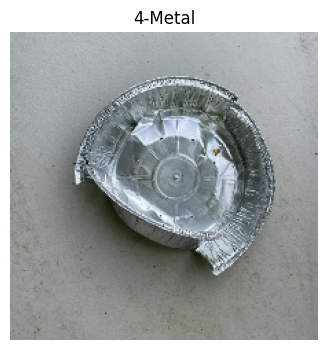

In [27]:
plt.figure(figsize=(4, 4))
plt.imshow(X_train_normalized[0])
plt.title(label_encoder.inverse_transform([y_train[0]])[0])
plt.axis("off")
plt.show()